# Figure 2 — Accessibility: single-cell GpC pseudobulk vs bulk ATAC at 250 kb

Compares **single-cell NOMe-HiC** GpC accessibility (**GCH** context), pooled per cell
type, against **bulk ENCODE ATAC-seq** in **GM12878** and **IMR90**, over 250 kb bins.

**Pipeline**
1. Read-weighted single-cell pseudobulk — Σ(methylated GCH reads)/Σ(total reads) pooled
   across all cells of a type (281 GM12878 + 160 IMR90), from
   `data_processing/mixture_cellline/03_pseudobulk/01_build_sc_pseudobulk_gch_250kb.sh`
   → `sc_pseudobulk_GCH_250kb.tsv.gz`.
2. Bulk ATAC signal binned to 250 kb, from
   `data_processing/bulk_others/02_process/02_bin_bulk_atac_250kb.py`
   → `bulk_atac_250kb.tsv`.
3. Bins with ≥20 GCH reads per cell type are ranked by the z-scored bulk ATAC
   difference, and the top 1,000 are shown.

The two ENCODE ATAC bigWigs differ in depth and scale, so each bulk track is z-scored on
log1p signal before differencing — without that the differential is globally biased.

Bulk ATAC is a continuous signal p-value rather than a rate, so agreement is measured by
correlation: **Spearman ρ = 0.767** on the differential across the plotted bins (§2).

Run with the **R (`scnomehic_diff`)** kernel.

**Published panels:** `fig2_gch250kb_pseudobulk_2row_heatmap.pdf` (§3) and
`fig2_gch250kb_2row_colorbars.pdf` (§3b).


In [1]:
# §1 Setup
suppressPackageStartupMessages({
  library(ggplot2); library(patchwork); library(scales); library(data.table)
})
set.seed(42)

FIG2 <- "/gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/fig2"


## §2 250 kb pseudobulk heatmap and correlation

Read-weighted single-cell GpC pseudobulk (Σmeth/Σtotal pooled per cell type) against bulk
ATAC, over the top-1000 differential 250 kb bins, per-bin mean-centred so magnitude is
kept. Each bulk track is z-scored on log1p signal before differencing, which removes the
depth difference between the two ENCODE bigWigs.

This cell also reports the **Spearman ρ on the differential** for exactly the bins the
published panel shows.


bins shown: 1000 | differential rho=0.767


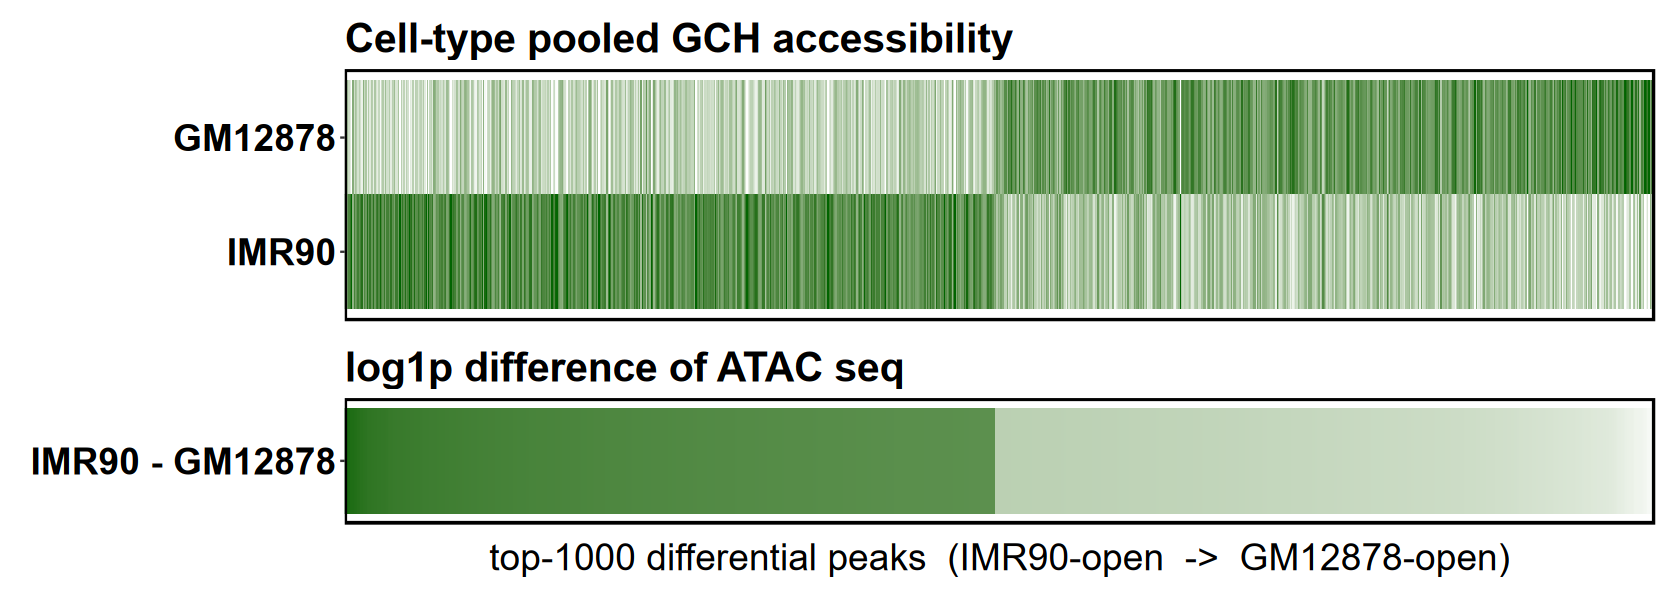

In [2]:
GCHACC   <- file.path(FIG2, "analysis/gch_acc_250kb")
G_OUTFIG <- file.path(GCHACC, "figures"); dir.create(G_OUTFIG, showWarnings=FALSE, recursive=TRUE)
pbk <- as.data.frame(fread(file.path(GCHACC, "sc_pseudobulk_GCH_250kb.tsv.gz")))
atk <- as.data.frame(fread(file.path(GCHACC, "bulk_atac_250kb.tsv")))
h <- merge(pbk, atk, by="bin_id", suffixes=c("",".bk"))
MINREADS <- 20; N_TOP <- 1000
h <- h[h$GM12878_total>=MINREADS & h$IMR90_total>=MINREADS &
       is.finite(h$GM12878_atac) & is.finite(h$IMR90_atac), ]
# per-track z-score (log1p) before differencing (the two ATAC bigWigs differ in depth); >0 = IMR-open
h$bulk_d <- scale(log1p(h$IMR90_atac))[,1] - scale(log1p(h$GM12878_atac))[,1]
h <- h[order(-abs(h$bulk_d)), ][seq_len(min(N_TOP, nrow(h))), ]
h <- h[order(-h$bulk_d), ]; bins_ord <- h$bin_id                       # IMR90-open -> GM12878-open

PB  <- rbind(GM12878=h$GM12878_beta, IMR90=h$IMR90_beta); colnames(PB) <- bins_ord
PBc <- sweep(PB, 2, colMeans(PB)); lim <- as.numeric(quantile(abs(PBc), 0.98))   # per-bin mean-centered
cat(sprintf("bins shown: %d | differential rho=%.3f\n", length(bins_ord),
            cor(h$IMR90_beta-h$GM12878_beta, h$bulk_d, method="spearman")))

# publication theme: larger text (matches methylation notebook pub_tile)
pub_tile <- theme(
  axis.text.x  = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y  = element_text(size = 22, face = "bold", colour = "black"),
  axis.title.x = element_text(size = 22, margin = margin(t = 9)),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
  plot.title = element_text(size = 24, face = "bold"), strip.background = element_blank(),
  legend.position = "none",
  plot.margin = margin(8, 10, 8, 10))

hm_long <- data.frame(type=factor(rep(rownames(PBc), times=ncol(PBc)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, each=2), levels=bins_ord), v=as.numeric(PBc[, bins_ord]))
bulk_long <- data.frame(ref=factor("IMR90 - GM12878"),
  bin=factor(bins_ord, levels=bins_ord), fold=h$bulk_d)
p_pb <- ggplot(hm_long, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-lim, lim),
                      oob=scales::squish, name="GpC acc.\n(centered)") +
  labs(title="Cell-type pooled GCH accessibility", x=NULL, y=NULL) + pub_tile
p_bk <- ggplot(bulk_long, aes(bin, ref, fill=fold)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=max(abs(h$bulk_d))*c(-1,1),
                      oob=scales::squish, name="ATAC\nz-diff") +
  labs(title="log1p difference of ATAC seq",
       x=sprintf("top-%d differential peaks  (IMR90-open  ->  GM12878-open)", length(bins_ord)), y=NULL) + pub_tile
comb <- (p_pb / p_bk) + plot_layout(heights=c(2, 1))
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_pseudobulk_heatmap.pdf"), comb, width=14, height=5.0)
options(repr.plot.width=14, repr.plot.height=5.0); comb


## §3 Two-row bulk variant — GM12878 and IMR90 shown separately

Same selection as §2, but the bulk ATAC ground truth is drawn as **two rows** — per-track
z(log1p signal) for GM12878 and IMR90 — rather than a single difference row. Both panels
use white → dark green. Z-scoring each track per cell line removes the depth and scale
difference between the two ENCODE bigWigs, so the rows are comparable.


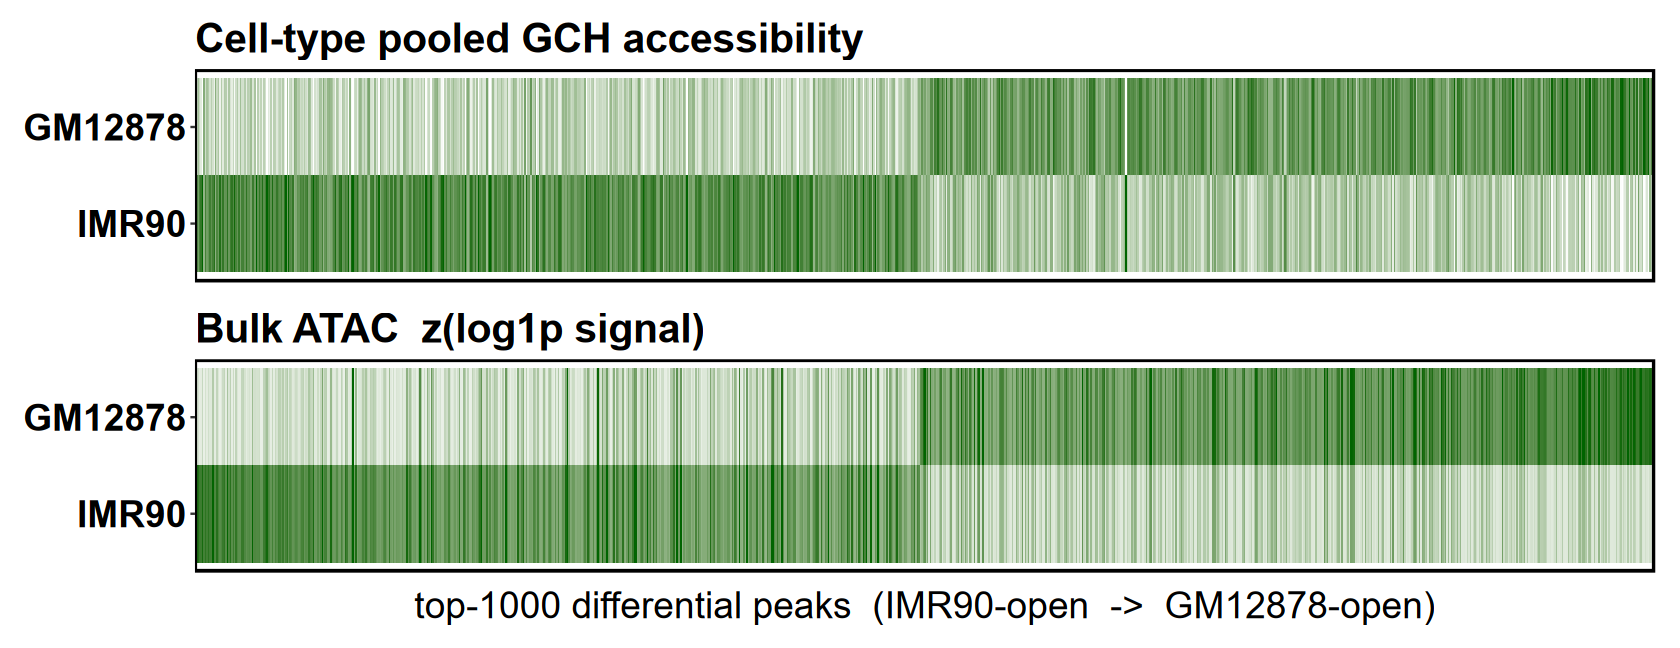

In [3]:
GCHACC   <- file.path(FIG2, "analysis/gch_acc_250kb")
G_OUTFIG <- file.path(GCHACC, "figures"); dir.create(G_OUTFIG, showWarnings=FALSE, recursive=TRUE)
pbk <- as.data.frame(fread(file.path(GCHACC, "sc_pseudobulk_GCH_250kb.tsv.gz")))
atk <- as.data.frame(fread(file.path(GCHACC, "bulk_atac_250kb.tsv")))
h <- merge(pbk, atk, by="bin_id", suffixes=c("",".bk"))
MINREADS <- 20; N_TOP <- 1000
h <- h[h$GM12878_total>=MINREADS & h$IMR90_total>=MINREADS &
       is.finite(h$GM12878_atac) & is.finite(h$IMR90_atac), ]
h$zG <- scale(log1p(h$GM12878_atac))[,1]; h$zI <- scale(log1p(h$IMR90_atac))[,1]; h$bulk_d <- h$zI - h$zG
h <- h[order(-abs(h$bulk_d)), ][seq_len(min(N_TOP, nrow(h))), ]
h <- h[order(-h$bulk_d), ]; bins_ord <- h$bin_id

PB  <- rbind(GM12878=h$GM12878_beta, IMR90=h$IMR90_beta); colnames(PB) <- bins_ord
PBc <- sweep(PB, 2, colMeans(PB)); lim <- as.numeric(quantile(abs(PBc), 0.98))
zl  <- max(abs(as.numeric(quantile(c(h$zG, h$zI), c(0.02, 0.98)))))

pub_tile <- theme(
  axis.text.x  = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y  = element_text(size = 22, face = "bold", colour = "black"),
  axis.title.x = element_text(size = 22, margin = margin(t = 9)),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
  plot.title = element_text(size = 24, face = "bold"), strip.background = element_blank(),
  legend.position = "none", plot.margin = margin(8, 10, 8, 10))

sc_long <- data.frame(type=factor(rep(rownames(PBc), times=ncol(PBc)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, each=2), levels=bins_ord), v=as.numeric(PBc[, bins_ord]))
bulk2 <- data.frame(type=factor(rep(c("GM12878","IMR90"), each=length(bins_ord)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, times=2), levels=bins_ord), v=c(h$zG, h$zI))
p_sc <- ggplot(sc_long, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-lim, lim), oob=scales::squish, name="GpC") +
  labs(title="Cell-type pooled GCH accessibility", x=NULL, y=NULL) + pub_tile
p_b2 <- ggplot(bulk2, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-zl, zl), oob=scales::squish, name="ATAC z(log1p)") +
  labs(title="Bulk ATAC  z(log1p signal)",
       x=sprintf("top-%d differential peaks  (IMR90-open  ->  GM12878-open)", length(bins_ord)), y=NULL) + pub_tile
comb <- (p_sc / p_b2) + plot_layout(heights=c(1, 1))
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_pseudobulk_2row_heatmap.pdf"), comb, width=14, height=5.4)
options(repr.plot.width=14, repr.plot.height=5.4); comb


### §3b Colorbars for the §3 heatmap

The §3 panels have their legends switched off for a clean publication figure, so the
colour scales are rendered here as standalone horizontal colorbars — the same
white → dark green ramp and the identical limits used in §3: one for single-cell **GCH
accessibility** (per-bin mean-centred, ±`lim`) and one for **bulk ATAC z(log1p signal)**
(±`zl`).

Run §3 first — this cell reuses its `lim`, `zl` and `G_OUTFIG`.


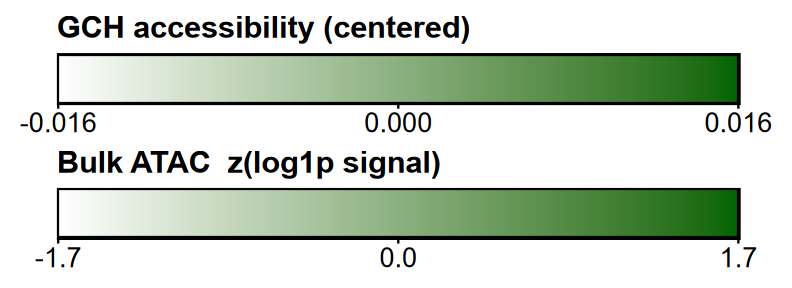

In [4]:
stopifnot(exists("lim"), exists("zl"), exists("G_OUTFIG"))   # from §3

cbar <- function(lo, hi, title, fmt="%.3f", n=256) {
  d <- data.frame(x = seq(lo, hi, length.out = n), y = 1)
  ggplot(d, aes(x, y, fill = x)) + geom_raster() +
    scale_fill_gradient(low = "white", high = "darkgreen", limits = c(lo, hi), guide = "none") +
    scale_x_continuous(breaks = c(lo, 0, hi), labels = function(b) sprintf(fmt, b), expand = c(0,0)) +
    scale_y_continuous(expand = c(0,0)) +
    labs(title = title, x = NULL, y = NULL) +
    theme(axis.text.x = element_text(size = 16, colour = "black"),
          axis.ticks.x = element_line(colour = "black"),
          axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.background = element_blank(), panel.grid = element_blank(),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
          plot.title = element_text(size = 18, face = "bold"),
          plot.margin = margin(4, 26, 4, 26))
}
cb1 <- cbar(-lim, lim, "GCH accessibility (centered)")
cb2 <- cbar(-zl,  zl,  "Bulk ATAC  z(log1p signal)", fmt = "%.1f")
cbs <- cb1 / cb2
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_2row_colorbars.pdf"), cbs, width = 6.6, height = 2.4)
options(repr.plot.width = 6.6, repr.plot.height = 2.4); cbs
